# 06 — Regression Models

I compare the three OLS specifications developed from Notebook 05, using the same parking spaces in every model. I keep the existing model estimates and specifications, then compare fit, price coefficients, and out-of-sample prediction before choosing a model to carry into diagnostics.

I reviewed `project1-1.pdf` and `Regression_Lecture0.ipynb`, `Regression_Lecture1.ipynb`, and `Regression_Lecture2.ipynb` in the local Downloads folder. The OLS, coefficient, dummy-variable, RMSE, and five-fold validation methods follow Lecture 1 (Sections 3.2, 4.1, and 6); multiple regression and AIC/BIC follow Lecture 2 (Sections 1.1 and 3.6). No new modeling method is introduced here.

## 1. Load and prepare the common sample

I load the unchanged Notebook 03 cross-section and retain FLAT and TOD meters, excluding the 79 JUMP spaces with incomparable price midpoints. I use the same 4,016 income-complete observations as Notebook 05 so changes across models reflect the controls rather than a changing sample. The 44 missing-income spaces are excluded for consistency with variable selection, even though none of these three models includes income.

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

parking = pd.read_csv(
    "../data/processed/parking_cross_section.csv",
    dtype={"SpaceID": str, "GEOID": str}
)

print("Original observations:", len(parking))
print("JUMP observations excluded:", (parking["RateType"] == "JUMP").sum())

parking = parking[parking["RateType"].isin(["FLAT", "TOD"])].copy()

print("FLAT + TOD observations:", len(parking))

parking["RateType_TOD"] = (parking["RateType"] == "TOD").astype(int)

variables = [
    "occupancy_rate",
    "price_midpoint",
    "time_limit_hours",
    "population_density",
    "nearby_restaurant_retail_count",
    "drive_alone_share",
    "transit_share",
    "RateType_TOD",
    "median_income"
]

print("Missing values before the common-sample restriction:")
print(parking[variables].isnull().sum())

data = parking[variables].dropna().copy()

print("Common comparison observations:", len(data))
print("Unique parking spaces:", parking.loc[data.index, "SpaceID"].nunique())

print("Duplicate parking spaces:", parking.loc[data.index, "SpaceID"].duplicated().sum())
print("Census tracts:", parking.loc[data.index, "GEOID"].nunique())
print("Missing values in the comparison data:", data.isnull().sum().sum())

Original observations: 4139
JUMP observations excluded: 79
FLAT + TOD observations: 4060
Missing values before the common-sample restriction:
occupancy_rate                     0
price_midpoint                     0
time_limit_hours                   0
population_density                 0
nearby_restaurant_retail_count     0
drive_alone_share                  0
transit_share                      0
RateType_TOD                       0
median_income                     44
dtype: int64
Common comparison observations: 4016
Unique parking spaces: 4016
Duplicate parking spaces: 0
Census tracts: 45
Missing values in the comparison data: 0


The checks give 4,139 original spaces, 4,060 FLAT + TOD spaces, and 4,016 unique spaces in the common sample, with no remaining missing values in the comparison variables. `RateType_TOD` equals one for TOD meters and zero for FLAT meters, the reference category. The outcome and the seven predictor definitions are unchanged.

## 2. Model 1: Price

I start with price alone to measure its unadjusted relationship with occupancy. `price_midpoint` is a stated hourly price for FLAT meters and a midpoint of hourly-rate endpoints for TOD meters, rather than the average payment made by drivers.

In [2]:

y = data["occupancy_rate"]

X1 = sm.add_constant(data[["price_midpoint"]])

model1 = sm.OLS(y, X1).fit()

print(model1.summary())


                            OLS Regression Results                            
Dep. Variable:         occupancy_rate   R-squared:                       0.157
Model:                            OLS   Adj. R-squared:                  0.157
Method:                 Least Squares   F-statistic:                     746.3
Date:                Thu, 22 Oct 2026   Prob (F-statistic):          7.41e-151
Time:                        20:44:53   Log-Likelihood:                 1243.8
No. Observations:                4016   AIC:                            -2484.
Df Residuals:                    4014   BIC:                            -2471.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const              0.4237      0.005     84.

The price coefficient is 0.05451: a $1 higher price proxy is associated with about **5.45 percentage points** higher occupancy. Its conventional OLS p-value is below 0.001, but this is an association across locations, not evidence that raising prices causes occupancy to increase.

## 3. Model 2: Add parking rules and local activity

I add time limits, population density, and nearby food-service/retail registrations to account for parking rules and local demand conditions. I retain the four-predictor specification already estimated here; the assignment's request for a 2–3-predictor middle model is flagged in the checklist below rather than silently changing this model.

In [3]:

X2 = sm.add_constant(data[[
    "price_midpoint",
    "time_limit_hours",
    "population_density",
    "nearby_restaurant_retail_count"
]])

model2 = sm.OLS(y, X2).fit()

print(model2.summary())


                            OLS Regression Results                            
Dep. Variable:         occupancy_rate   R-squared:                       0.244
Model:                            OLS   Adj. R-squared:                  0.243
Method:                 Least Squares   F-statistic:                     323.3
Date:                Thu, 22 Oct 2026   Prob (F-statistic):          2.05e-241
Time:                        20:44:53   Log-Likelihood:                 1462.5
No. Observations:                4016   AIC:                            -2915.
Df Residuals:                    4011   BIC:                            -2884.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                                     coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
const       

The price coefficient rises to 0.06064, or about **6.06 percentage points per $1**, after adding these controls. Population density is positively associated with occupancy, while the registration-count coefficient is negative conditional on the other variables. Those conditional relationships can differ from the pairwise EDA correlations.

## 4. Model 3: Preferred seven-variable specification

I add drive-alone share, transit share, and the TOD indicator to Model 2. This is the seven-variable specification chosen in Notebook 05 after reviewing economic relevance, Boruta, Mallows' Cp, and VIF; all seven were Boruta-confirmed and their selected-model VIFs were below two. It was a parsimonious choice, not the global minimum-Cp subset, and its performance still needs comparison here.

In [4]:

X3 = sm.add_constant(data[[
    "price_midpoint",
    "time_limit_hours",
    "population_density",
    "nearby_restaurant_retail_count",
    "drive_alone_share",
    "transit_share",
    "RateType_TOD"
]])

model3 = sm.OLS(y, X3).fit()

print(model3.summary())


                            OLS Regression Results                            
Dep. Variable:         occupancy_rate   R-squared:                       0.274
Model:                            OLS   Adj. R-squared:                  0.272
Method:                 Least Squares   F-statistic:                     215.7
Date:                Thu, 22 Oct 2026   Prob (F-statistic):          1.25e-272
Time:                        20:44:53   Log-Likelihood:                 1543.4
No. Observations:                4016   AIC:                            -3071.
Df Residuals:                    4008   BIC:                            -3020.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                                     coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
const       

The price coefficient remains positive at 0.05563. Time limit and transit share are not statistically significant at 5% in this specification; I keep them as specified rather than changing the model after seeing these p-values. All standard errors and confidence intervals here are conventional OLS estimates, with dependence and variance assumptions left for Notebook 07.

## 5. Compare in-sample model performance

I compare all three models on the same outcome and observations, counting predictors without the intercept. Higher adjusted R² and lower AIC/BIC generally favor a model, while RMSE summarizes fitted errors in occupancy-rate units. This RMSE is in-sample fit, not held-out prediction performance.

In [5]:

comparison = pd.DataFrame({
    "Model": ["Model 1", "Model 2", "Model 3"],
    "Predictors": [1, 4, 7],
    "Adjusted R2": [
        model1.rsquared_adj,
        model2.rsquared_adj,
        model3.rsquared_adj
    ],
    "AIC": [
        model1.aic,
        model2.aic,
        model3.aic
    ],
    "BIC": [
        model1.bic,
        model2.bic,
        model3.bic
    ]
})

comparison["N"] = [int(model1.nobs), int(model2.nobs), int(model3.nobs)]
comparison["R2"] = [model1.rsquared, model2.rsquared, model3.rsquared]
comparison["In-sample RMSE"] = [
    np.sqrt(np.mean(model1.resid ** 2)),
    np.sqrt(np.mean(model2.resid ** 2)),
    np.sqrt(np.mean(model3.resid ** 2))
]
comparison = comparison[[
    "Model", "Predictors", "N", "R2", "Adjusted R2", "AIC", "BIC", "In-sample RMSE"
]]

comparison.round(5)


,Model,Predictors,N,R2,Adjusted R2,AIC,BIC,In-sample RMSE
0,Model 1,1,4016,0.15678,0.15657,-2483.67051,-2471.07443,0.17752
1,Model 2,4,4016,0.24379,0.24303,-2915.05190,-2883.56169,0.16811
2,Model 3,7,4016,0.27362,0.27235,-3070.71241,-3020.32808,0.16476


Adjusted R² rises from 0.157 to 0.243 to 0.272, and both AIC and BIC fall as controls are added. Negative AIC/BIC values are valid; the lower, more negative values are preferred on this common sample. Model 3 leads on these criteria, but I also check prediction rather than choosing it simply because it has more predictors.

## 6. Compare the price coefficients

I place the price estimates, conventional standard errors, p-values, and 95% confidence intervals side by side. A coefficient is measured in occupancy-rate units per dollar, so multiplying it by 100 gives the associated percentage-point difference. Scientific notation keeps very small p-values visible instead of rounding them to zero.

In [6]:

price_comparison = pd.DataFrame({
    "Model": ["Model 1", "Model 2", "Model 3"],
    "Price Coefficient": [
        model1.params["price_midpoint"],
        model2.params["price_midpoint"],
        model3.params["price_midpoint"]
    ],
    "P-value": [
        model1.pvalues["price_midpoint"],
        model2.pvalues["price_midpoint"],
        model3.pvalues["price_midpoint"]
    ]
})

price_comparison["Standard error"] = [
    model1.bse["price_midpoint"],
    model2.bse["price_midpoint"],
    model3.bse["price_midpoint"]
]
price_comparison["95% lower"] = [
    model1.conf_int().loc["price_midpoint", 0],
    model2.conf_int().loc["price_midpoint", 0],
    model3.conf_int().loc["price_midpoint", 0]
]
price_comparison["95% upper"] = [
    model1.conf_int().loc["price_midpoint", 1],
    model2.conf_int().loc["price_midpoint", 1],
    model3.conf_int().loc["price_midpoint", 1]
]
price_comparison = price_comparison[[
    "Model", "Price Coefficient", "Standard error", "P-value", "95% lower", "95% upper"
]]

price_comparison.style.format({
    "Price Coefficient": "{:.5f}", "Standard error": "{:.5f}",
    "P-value": "{:.3e}", "95% lower": "{:.5f}", "95% upper": "{:.5f}"
})


,Model,Price Coefficient,Standard error,P-value,95% lower,95% upper
0,Model 1,0.05451,0.00200,7.414e-151,0.05060,0.05843
1,Model 2,0.06064,0.00237,4.664e-134,0.05600,0.06528
2,Model 3,0.05563,0.00236,4.731e-115,0.05100,0.06026


The associated difference is **5.45**, **6.06**, and **5.56 percentage points per $1** in Models 1–3. All three estimates remain positive and significant at 5% under conventional OLS inference; adding the full controls does not reverse the sign. Demand-responsive pricing and omitted location characteristics remain plausible explanations, so this is not a causal price effect.

## 7. Interpret Model 3

I report each coefficient with its uncertainty, then use changes that are easier to interpret for density, registrations, and commuting shares. These comparisons hold the other included variables constant. Statistical significance does not establish causality or tell us whether a magnitude is economically large.

In [7]:
coefficient_table = pd.DataFrame({
    "Coefficient": model3.params,
    "Standard error": model3.bse,
    "P-value": model3.pvalues,
    "95% lower": model3.conf_int()[0],
    "95% upper": model3.conf_int()[1]
})
coefficient_table.index.name = "Variable"

coefficient_table.style.format({
    "Coefficient": "{:.6g}", "Standard error": "{:.6g}",
    "P-value": "{:.3e}", "95% lower": "{:.6g}", "95% upper": "{:.6g}"
})

,Coefficient,Standard error,P-value,95% lower,95% upper
Variable,,,,,
const,0.456337,0.0157939,6.470e-167,0.425373,0.487302
price_midpoint,0.0556328,0.00236136,4.731e-115,0.0510033,0.0602624
time_limit_hours,0.00487929,0.00294796,9.797e-02,-0.000900361,0.0106589
population_density,4.57052e-06,2.21771e-07,8.803e-90,4.13573e-06,5.00531e-06
nearby_restaurant_retail_count,-0.000321282,2.29852e-05,2.189e-43,-0.000366346,-0.000276218
drive_alone_share,-0.198101,0.0208314,3.195e-21,-0.238942,-0.15726
transit_share,0.0196471,0.0468362,6.749e-01,-0.072178,0.111472
RateType_TOD,0.0330042,0.00731608,6.631e-06,0.0186606,0.0473478


- **Price:** a $1 higher proxy is associated with **5.56 percentage points** higher occupancy (95% CI: **5.10 to 6.03**). This is a sizeable conditional difference, with the timing and endogeneity qualifications already noted.
- **Time limit:** an additional permitted hour is associated with **0.49 percentage points** higher occupancy, but the interval spans zero (−0.09 to 1.07; p = 0.098).
- **Population density:** an additional **1,000 people per square mile** is associated with **0.46 percentage points** higher occupancy (95% CI: 0.41 to 0.50).
- **Food-service/retail activity:** **100 additional registrations within 0.25 miles** are associated with **3.21 percentage points lower** occupancy (95% CI: −3.66 to −2.76). This conditional association does not mean that opening businesses reduces parking demand.

- **Drive-alone share:** a **10-percentage-point increase** is associated with **1.98 percentage points lower** occupancy (95% CI: −2.39 to −1.57).
- **Transit share:** a **10-percentage-point increase** is associated with **0.20 percentage points higher** occupancy, with substantial uncertainty (95% CI: −0.72 to 1.11; p = 0.675). This is not clear evidence of a nonzero conditional relationship.
- **TOD indicator:** TOD spaces have **3.30 percentage points higher** predicted occupancy than FLAT spaces with the same included covariates (95% CI: 1.87 to 4.73).

The intercept is 0.45634, the fitted occupancy for a FLAT meter when all numeric predictors are zero. That combination is outside the observed support, so the intercept has little standalone economic meaning.

## 8. Compare five-fold prediction performance

Following Lecture 1, I use shuffled five-fold validation with seed 10 and the same folds for each model. `cross_val_score` fits a fresh `LinearRegression` with an intercept on each training fold and predicts only its held-out fold; it does not use the full-sample `model1`, `model2`, or `model3` fits. No scaling, imputation, or new predictor selection is performed in this comparison.

In [8]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import LinearRegression

folds = KFold(n_splits=5, shuffle=True, random_state=10)

cv1 = -cross_val_score(
    LinearRegression(), data[X1.columns.drop("const")], y,
    cv=folds, scoring="neg_root_mean_squared_error"
)
cv2 = -cross_val_score(
    LinearRegression(), data[X2.columns.drop("const")], y,
    cv=folds, scoring="neg_root_mean_squared_error"
)
cv3 = -cross_val_score(
    LinearRegression(), data[X3.columns.drop("const")], y,
    cv=folds, scoring="neg_root_mean_squared_error"
)

cv_results = pd.DataFrame({
    "Fold": range(1, 6),
    "Model 1 RMSE": cv1,
    "Model 2 RMSE": cv2,
    "Model 3 RMSE": cv3
})
cv_results.round(5)

,Fold,Model 1 RMSE,Model 2 RMSE,Model 3 RMSE
0,1,0.17539,0.16609,0.16293
1,2,0.17974,0.17098,0.16667
2,3,0.17911,0.17102,0.16712
3,4,0.17685,0.16534,0.16425
4,5,0.17673,0.16827,0.16561


In [9]:
cv_summary = pd.DataFrame({
    "Model": ["Model 1", "Model 2", "Model 3"],
    "Mean CV RMSE": [cv1.mean(), cv2.mean(), cv3.mean()],
    "SD across folds": [cv1.std(ddof=1), cv2.std(ddof=1), cv3.std(ddof=1)]
})
cv_summary.round(5)

,Model,Mean CV RMSE,SD across folds
0,Model 1,0.17756,0.00181
1,Model 2,0.16834,0.00266
2,Model 3,0.16532,0.00173


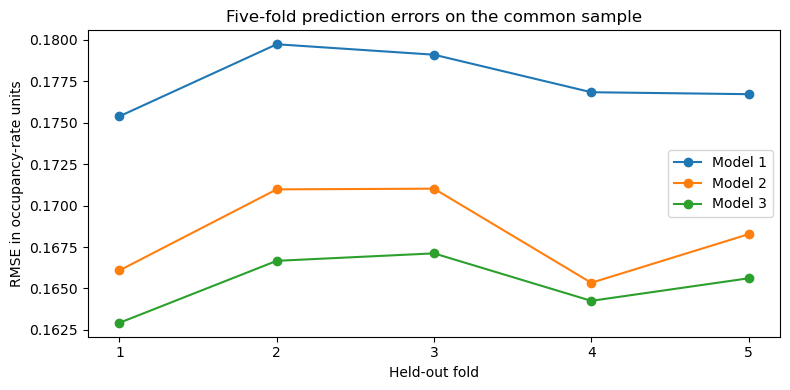

In [10]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, 6), cv1, marker="o", label="Model 1")
plt.plot(range(1, 6), cv2, marker="o", label="Model 2")
plt.plot(range(1, 6), cv3, marker="o", label="Model 3")
plt.xticks(range(1, 6))
plt.xlabel("Held-out fold")
plt.ylabel("RMSE in occupancy-rate units")
plt.title("Five-fold prediction errors on the common sample")
plt.legend()
plt.tight_layout()
plt.show()

Mean held-out RMSE falls from **0.17756** to **0.16834** to **0.16532**. Model 3 performs best in each of these five folds; its mean error is about **16.53 percentage points in root-mean-square terms**, an improvement of about **0.30 percentage points** over Model 2. The fold standard deviations describe variation across these splits, not standard errors for a formal test of model differences.

The 4,016 spaces lie in 45 Census tracts, so random folds can put neighboring spaces and the same tract in training and test data. This evaluates prediction for held-out spaces from the observed setting, not entirely new neighborhoods. It also evaluates the three fixed specifications rather than the full variable-selection process; Notebook 05 used the common sample before this comparison, so these are not untouched post-selection validation results.

## 9. Choose a model to carry into diagnostics

I combine the fit and held-out error summaries before making a provisional choice. The criteria evaluate different tradeoffs, so I show their preferred models separately. The comparison is conditional on the same 4,016 observations and the three specified models.

In [11]:
final_comparison = comparison.merge(cv_summary, on="Model", validate="one_to_one")
final_comparison.round(5)

,Model,Predictors,N,R2,Adjusted R2,AIC,BIC,In-sample RMSE,Mean CV RMSE,SD across folds
0,Model 1,1,4016,0.15678,0.15657,-2483.67051,-2471.07443,0.17752,0.17756,0.00181
1,Model 2,4,4016,0.24379,0.24303,-2915.05190,-2883.56169,0.16811,0.16834,0.00266
2,Model 3,7,4016,0.27362,0.27235,-3070.71241,-3020.32808,0.16476,0.16532,0.00173


In [12]:
ranked = final_comparison.set_index("Model")
winners = pd.Series({
    "Highest adjusted R2": ranked["Adjusted R2"].idxmax(),
    "Lowest AIC": ranked["AIC"].idxmin(),
    "Lowest BIC": ranked["BIC"].idxmin(),
    "Lowest mean CV RMSE": ranked["Mean CV RMSE"].idxmin()
}, name="Preferred model")
winners

Highest adjusted R2    Model 3
Lowest AIC             Model 3
Lowest BIC             Model 3
Lowest mean CV RMSE    Model 3
Name: Preferred model, dtype: object

Model 3 has the highest adjusted R² (**0.27235**), lowest AIC (**−3,070.71**), lowest BIC (**−3,020.33**), and lowest mean CV RMSE (**0.16532**). It explains about **27.36%** of the sample variation in occupancy, so substantial variation remains unexplained. The price estimate stays positive and conventionally significant in every model.

I carry Model 3 forward because it improves the fit criteria and prediction in this comparison, not simply because it has seven predictors. Its prediction gain over Model 2 is modest, and time limit and transit share remain individually insignificant at 5%. This is a provisional choice for diagnostics, not a claim that the assumptions hold or that every included variable is statistically significant.

## 10. Limitations, assignment check, and next steps

The outcome is August 2025 occupancy, while prices and business registrations come from October 2026. TOD midpoint summarizes hourly-rate endpoints rather than actual payments, and prices may respond to demand, creating endogeneity. Registration counts also need not represent unique storefronts or businesses active during the outcome month.

Several spaces share tracts and nearby demand conditions, so the conventional standard errors need further examination. Large condition numbers in the summaries can reflect differing variable units as well as collinearity; they are not a diagnosis by themselves, and Notebook 05's selected-model VIFs were below two. OLS predictions are not constrained to the occupancy interval of zero to one.

Notebook 07 will examine residuals, regression assumptions, influential observations, and robustness. Planned sensor comparisons cover 12/24/48-hour maximum intervals, 20/25/28 active days, and Sunday-reporting differences; none of those datasets or diagnostics is rebuilt here. The five-fold comparison above already supplies the requested initial held-out prediction check and need not be repeated without a reason.

### Assignment checklist

This checklist follows `project1-1.pdf` (130-point rubric). Completing Notebook 06 does not complete the assignment.

| Requirement | Status and location |
|---|---|
| At least 500 observations, five potential predictors, cross-sectional OLS setting | Completed in the constructed data and Notebooks 04–06; the common comparison has 4,016 spaces |
| Source, period, sample and variable definitions; descriptive statistics; histograms, boxplots, scatterplots and correlation heatmap | Completed in Notebooks 01–04, with the comparison-sample decision shown here |
| IQR outlier inspection and missingness patterns | Completed in Notebook 04; standardized-residual checks and missingness/sample sensitivity remain for later work |
| Q-Q plots, density plots and Pandas Profiling discussion for EDA | Not present in the saved Notebook 04; still outstanding, without modifying that notebook here |
| Boruta, Mallows' Cp and VIF | Completed in the saved Notebook 05; its selection results are preserved |
| Three competing models with explicit predictors and a common sample | Completed here for the requested specifications; the middle-model predictor-count mismatch is noted below |
| AIC, BIC, adjusted R² and five- or ten-fold validation | Completed here using common observations and five fixed, shuffled folds |
| Coefficients, standard errors, p-values, economic units and key 95% intervals | Completed here, including all Model 3 coefficients; final presentation remains for Notebook 08 |
| Economic/statistical justification of the model carried forward | Provisional comparison completed here; final choice remains subject to diagnostics and the specification issues below |
| Residual/fitted and scale-location plots; RESET; Breusch–Pagan/White; residual Q-Q, Jarque–Bera and histogram; Cook's distance, leverage and DFBETAS | Reserved for Notebook 07; summary-output statistics alone do not complete these diagnostics |
| Bootstrap coefficient estimates with 1,000 replications; comparison with OLS | Reserved for Notebook 07 |
| Economic motivation with at least two academic sources, expected signs/magnitudes, policy/external-validity discussion, final conclusions and references | Final report work for Notebook 08; complete submission content has not been verified here |
| Reproducible code and fixed seeds | Notebook 06 runs from the saved CSV; validation uses seed 10; no dataset is overwritten |
| One group report with names, Python source and all required sections, submitted as PDF or HTML | Final submission remains outstanding |

**Specification issues to resolve:** the assignment asks for 2–3 predictors in Model 2, while the approved model has four. It also describes Model 3 in terms of statistically significant predictors, while time limit and transit share are not significant at 5% here. I preserve the requested models and Notebook 05 selection results; any change or justification of these differences needs an explicit decision before final submission.

**Lecture alignment:** all statistical methods implemented here are demonstrated in Lectures 1–2. No advanced method was added to fill an assignment gap, and no source data, earlier notebook, or Notebook 07 analysis is changed.